# Supermarket Sales Analysis
**IBM SkillsBuild – Data Analytics with AI | Academic Internship Program (BharatCares × AICTE)**

**Author:** pp  |  **Dataset:** `supermarket_sales.csv` (500 transactions, Jan–Jul 2026, 4 branches)

## Objective
Analyse supermarket sales data to understand products, branches, categories, customers, payments and ratings, and convert the findings into business decisions.

## Workflow
1. Load data  →  2. Data quality checks  →  3. Feature engineering  →  4. KPIs  →  5. Analysis & charts  →  6. Insights & recommendations

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
os.makedirs("charts", exist_ok=True)

def rupee(x, pos=None):
    return f"₹{x:,.0f}"

## 2. Load the Dataset

In [2]:
df = pd.read_csv("supermarket_sales.csv")
print("Shape:", df.shape)
df.head()

Shape: (500, 13)


,Invoice ID,Date,Branch,City,Customer Type,Gender,Product,Category,Quantity,Unit Price,Payment,Rating,Sales
0,INV0001,2026-06-01,A,Jaipur,Member,Male,Milk,Dairy,4,57.13,UPI,3.8,228.52
1,INV0002,2026-02-26,A,Jaipur,Normal,Male,Rice,Grocery,9,66.85,Net Banking,3.9,601.65
2,INV0003,2026-02-09,C,Mumbai,Normal,Female,Milk,Dairy,3,57.28,Card,3.4,171.84
3,INV0004,2026-01-12,C,Mumbai,Member,Female,Shampoo,Personal Care,2,168.27,Card,4.5,336.54
4,INV0005,2026-06-30,A,Jaipur,Normal,Female,Apples,Fruits,5,130.57,Cash,3.1,652.85


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice ID     500 non-null    str    
 1   Date           500 non-null    str    
 2   Branch         500 non-null    str    
 3   City           500 non-null    str    
 4   Customer Type  500 non-null    str    
 5   Gender         500 non-null    str    
 6   Product        500 non-null    str    
 7   Category       500 non-null    str    
 8   Quantity       500 non-null    int64  
 9   Unit Price     500 non-null    float64
 10  Payment        500 non-null    str    
 11  Rating         500 non-null    float64
 12  Sales          500 non-null    float64
dtypes: float64(3), int64(1), str(9)
memory usage: 50.9 KB


**Column description**

| Column | Meaning |
|---|---|
| Invoice ID | Unique transaction ID |
| Date | Date of sale |
| Branch / City | Store branch (A–D) and its city |
| Customer Type | Member or Normal |
| Gender | Customer gender |
| Product / Category | Item sold and its category |
| Quantity / Unit Price | Units bought and price per unit (₹) |
| Payment | UPI, Net Banking, Card or Cash |
| Rating | Customer rating (1–5) |
| Sales | Transaction value (₹) |

## 3. Data Quality Checks

In [4]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows       :", df.duplicated().sum())
print("Duplicate Invoice IDs:", df["Invoice ID"].duplicated().sum())

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Verify Sales = Quantity x Unit Price
df["Calc_Sales"] = (df["Quantity"] * df["Unit Price"]).round(2)
mismatch = (df["Calc_Sales"] - df["Sales"]).abs() > 0.01
print("Rows where Sales != Quantity x Unit Price:", mismatch.sum())

# Range checks
print("\nRating range  :", df["Rating"].min(), "-", df["Rating"].max())
print("Quantity range:", df["Quantity"].min(), "-", df["Quantity"].max())
print("Date range    :", df["Date"].min().date(), "to", df["Date"].max().date())
print("\nBranch-City mapping is one-to-one:", df.groupby("Branch")["City"].nunique().eq(1).all())

Missing values per column:
Invoice ID       0
Date             0
Branch           0
City             0
Customer Type    0
Gender           0
Product          0
Category         0
Quantity         0
Unit Price       0
Payment          0
Rating           0
Sales            0
dtype: int64

Duplicate rows       : 0
Duplicate Invoice IDs: 0
Rows where Sales != Quantity x Unit Price: 0

Rating range  : 3.0 - 5.0
Quantity range: 1 - 10
Date range    : 2026-01-01 to 2026-07-01

Branch-City mapping is one-to-one: True


**Result:** no missing values, no duplicates, all Sales values equal Quantity × Unit Price, and ratings/quantities are in valid ranges. The data is clean and needs no imputation.

## 4. Feature Engineering

In [5]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)
df["Month_Name"] = df["Date"].dt.strftime("%b")
df["Weekday"] = df["Date"].dt.day_name()
df = df.drop(columns=["Calc_Sales"])
df.describe().round(2)

,Date,Quantity,Unit Price,Rating,Sales
count,500,500.00,500.00,500.00,500.00
mean,2026-04-03 12:25:55.200000,5.54,88.66,3.99,488.82
min,2026-01-01 00:00:00,1.00,27.67,3.00,28.61
25%,2026-02-17 00:00:00,3.00,43.96,3.50,189.21
50%,2026-04-09 00:00:00,5.50,61.88,4.00,335.91
75%,2026-05-17 06:00:00,8.00,128.57,4.50,609.88
max,2026-07-01 00:00:00,10.00,236.71,5.00,2114.82
std,NaN,2.88,57.28,0.57,437.33


## 5. Key Performance Indicators

In [6]:
total_sales = df["Sales"].sum()
kpi = pd.Series({
    "Total Transactions": len(df),
    "Total Sales (₹)": round(total_sales, 2),
    "Average Transaction Value (₹)": round(df["Sales"].mean(), 2),
    "Total Units Sold": int(df["Quantity"].sum()),
    "Average Rating (out of 5)": round(df["Rating"].mean(), 2),
})
kpi.to_frame("Value")

,Value
Total Transactions,500.00
Total Sales (₹),244411.08
Average Transaction Value (₹),488.82
Total Units Sold,2768.00
Average Rating (out of 5),3.99


## 6. Analysis

### Q1. Which product generates the highest sales?

,Sales,Units,Transactions,Avg_Rating
Product,,,,
Cheese,27906.30,126,26,3.98
Coffee,27694.87,153,24,3.86
Shampoo,27497.48,152,27,3.92
Cooking Oil,21525.06,142,26,3.97
Tea,17681.59,146,29,4.02
Apples,17057.41,119,20,3.86
Face Wash,11946.85,100,19,3.90
Rice,11754.17,167,29,3.84
Cold Drink,10731.78,166,29,3.98


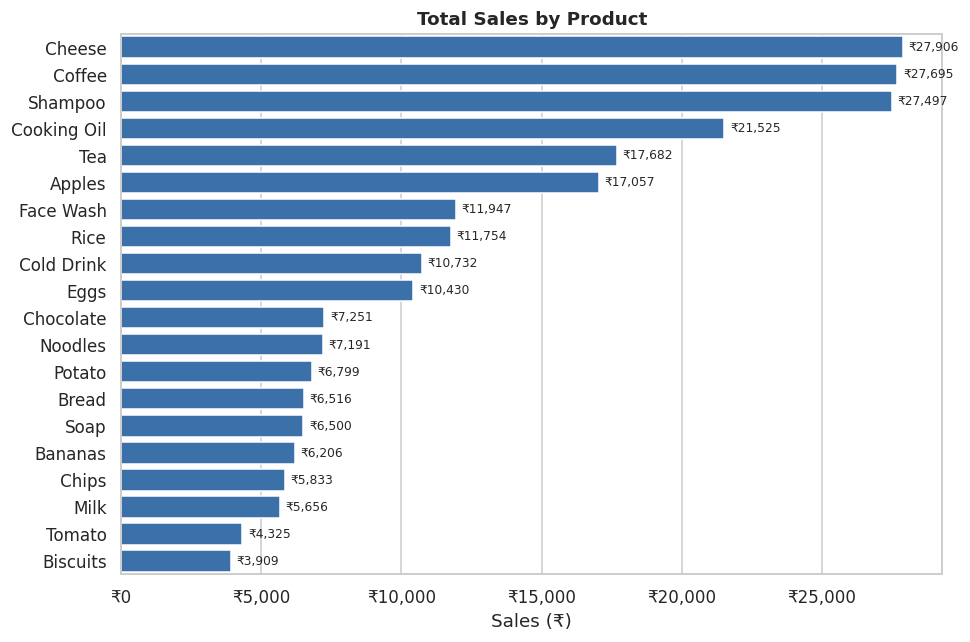

Top product: Cheese with ₹27,906.30


In [7]:
prod = df.groupby("Product").agg(Sales=("Sales","sum"), Units=("Quantity","sum"),
                                 Transactions=("Invoice ID","count"),
                                 Avg_Rating=("Rating","mean")).sort_values("Sales", ascending=False).round(2)
display(prod)

fig, ax = plt.subplots(figsize=(9,6))
sns.barplot(x=prod["Sales"], y=prod.index, ax=ax, color="#2a6fbb")
ax.xaxis.set_major_formatter(rupee)
ax.set_title("Total Sales by Product"); ax.set_xlabel("Sales (₹)"); ax.set_ylabel("")
for i, v in enumerate(prod["Sales"]): ax.text(v+200, i, f"₹{v:,.0f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig("charts/01_sales_by_product.png"); plt.show()
print(f"Top product: {prod.index[0]} with ₹{prod['Sales'].iloc[0]:,.2f}")

The top three products — **Cheese, Coffee and Shampoo** — are very close (about ₹27.5k–27.9k each). All three are high unit-price items; the gap between #1 and #2 is under 1%, so these should be treated as a group of top earners.

### Q2. Which branch performs best?

,,Sales,Transactions,Avg_Sale,Avg_Rating,Share_%
Branch,City,,,,,
C,Mumbai,72469.45,143,506.78,4.05,29.7
B,Delhi,64116.26,133,482.08,3.98,26.2
D,Bengaluru,55468.29,119,466.12,4.09,22.7
A,Jaipur,52357.08,105,498.64,3.84,21.4


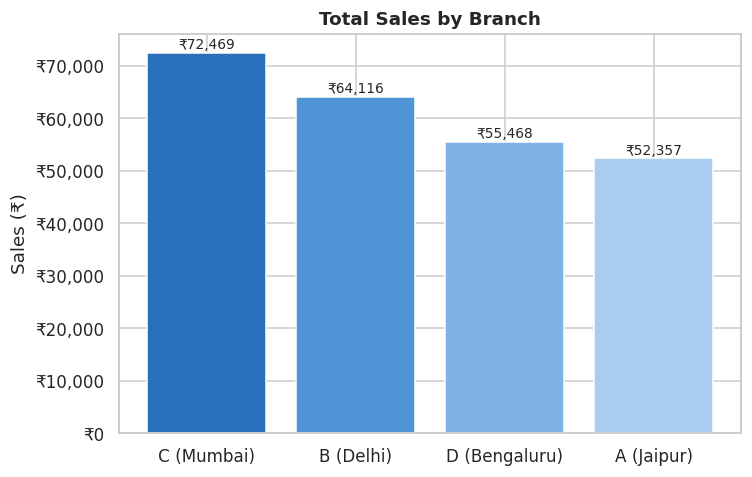

In [8]:
branch = df.groupby(["Branch","City"]).agg(Sales=("Sales","sum"), Transactions=("Invoice ID","count"),
                                           Avg_Sale=("Sales","mean"), Avg_Rating=("Rating","mean")
                                          ).sort_values("Sales", ascending=False).round(2)
branch["Share_%"] = (branch["Sales"]/total_sales*100).round(1)
display(branch)

labels = [f"{b} ({c})" for b, c in branch.index]
fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(labels, branch["Sales"], color=["#2a6fbb","#4f95d6","#7fb3e6","#a9cdf0"])
ax.yaxis.set_major_formatter(rupee)
ax.set_title("Total Sales by Branch"); ax.set_ylabel("Sales (₹)")
for b_, v in zip(bars, branch["Sales"]): ax.text(b_.get_x()+b_.get_width()/2, v+800, f"₹{v:,.0f}", ha="center", fontsize=9)
plt.tight_layout(); plt.savefig("charts/02_sales_by_branch.png"); plt.show()

**Branch C (Mumbai)** leads with ₹72,469 (about 29.7% of all sales). Branch A (Jaipur) is the lowest at ₹52,357.

#### Why does Branch C lead? Branch × Category sales

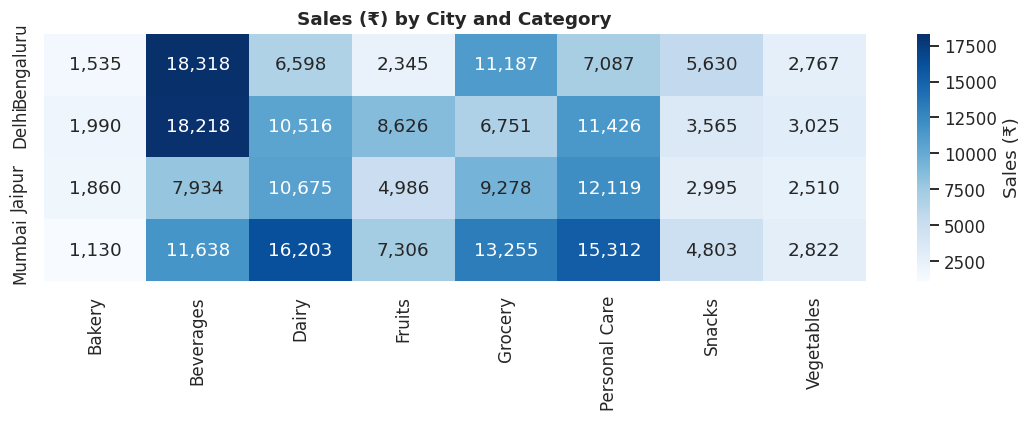

In [9]:
pivot = df.pivot_table(index="City", columns="Category", values="Sales", aggfunc="sum").round(0)
fig, ax = plt.subplots(figsize=(10,4))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="Blues", ax=ax, cbar_kws={"label":"Sales (₹)"})
ax.set_title("Sales (₹) by City and Category"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("charts/03_city_category_heatmap.png"); plt.show()

In [10]:
# Branch C vs others: transactions and average basket
summary = df.groupby("City").agg(Transactions=("Invoice ID","count"), Avg_Sale=("Sales","mean")).round(2)
summary.sort_values("Transactions", ascending=False)

,Transactions,Avg_Sale
City,,
Mumbai,143,506.78
Delhi,133,482.08
Bengaluru,119,466.12
Jaipur,105,498.64


Branch C's lead comes mainly from **more transactions** (143, against 105 in Branch A), not from a bigger bill — its average sale (₹507) is close to Jaipur's (₹499). Transaction volume is the factor to study (footfall, location, offers, product mix).

### Q3. Which category sells the most?

,Sales,Units,Transactions,Avg_Unit_Price,Share_%
Category,,,,,
Beverages,56108.24,465,82,118.38,23.0
Personal Care,45943.96,399,73,113.86,18.8
Dairy,43992.00,345,68,128.85,18.0
Grocery,40470.47,439,82,90.74,16.6
Fruits,23263.17,223,44,97.12,9.5
Snacks,16992.97,443,75,37.66,7.0
Vegetables,11124.17,290,48,39.45,4.6
Bakery,6516.10,164,28,39.90,2.7


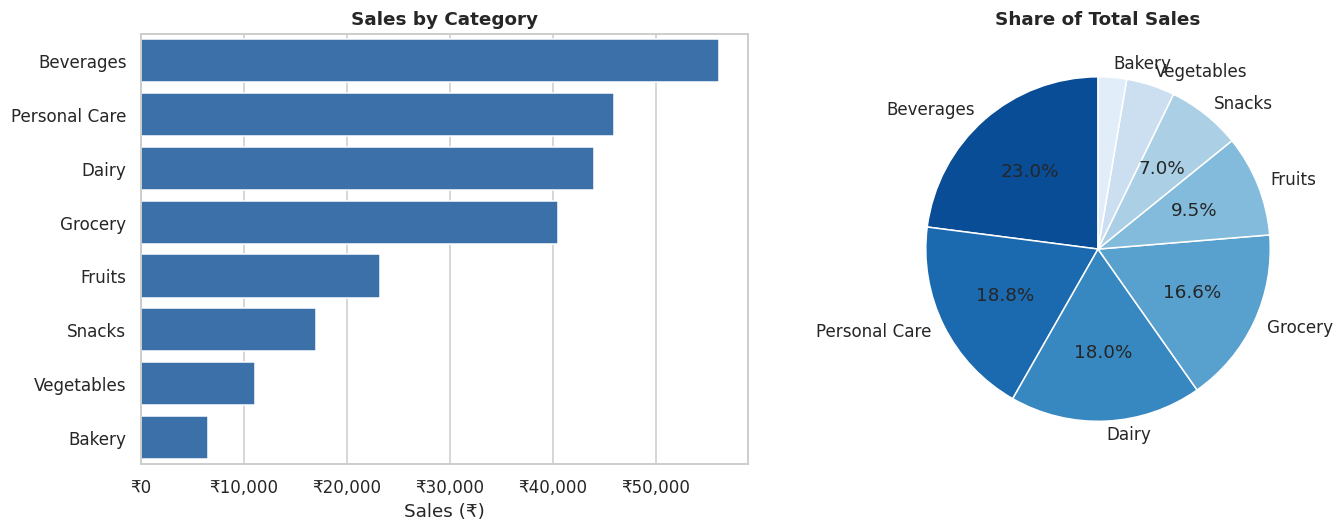

In [11]:
cat = df.groupby("Category").agg(Sales=("Sales","sum"), Units=("Quantity","sum"),
                                 Transactions=("Invoice ID","count"),
                                 Avg_Unit_Price=("Unit Price","mean")).sort_values("Sales", ascending=False).round(2)
cat["Share_%"] = (cat["Sales"]/total_sales*100).round(1)
display(cat)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
sns.barplot(x=cat["Sales"], y=cat.index, ax=axes[0], color="#2a6fbb")
axes[0].xaxis.set_major_formatter(rupee); axes[0].set_title("Sales by Category"); axes[0].set_xlabel("Sales (₹)"); axes[0].set_ylabel("")
axes[1].pie(cat["Sales"], labels=cat.index, autopct=lambda p: f"{p:.1f}%" if p > 5 else "", startangle=90, labeldistance=1.08, colors=sns.color_palette("Blues_r", len(cat)))
axes[1].set_title("Share of Total Sales")
plt.tight_layout(); plt.savefig("charts/04_sales_by_category.png"); plt.show()

**Beverages** lead (₹56,108, 23%), followed by Personal Care and Dairy. Bakery and Vegetables are the smallest — their unit prices are only about ₹40, so even steady volume adds little revenue.

### Q4. What is the most popular payment method?

,Transactions,Share_%,Sales
Payment,,,
UPI,127,25.4,67910.33
Net Banking,126,25.2,65194.93
Card,125,25.0,57265.64
Cash,122,24.4,54040.18


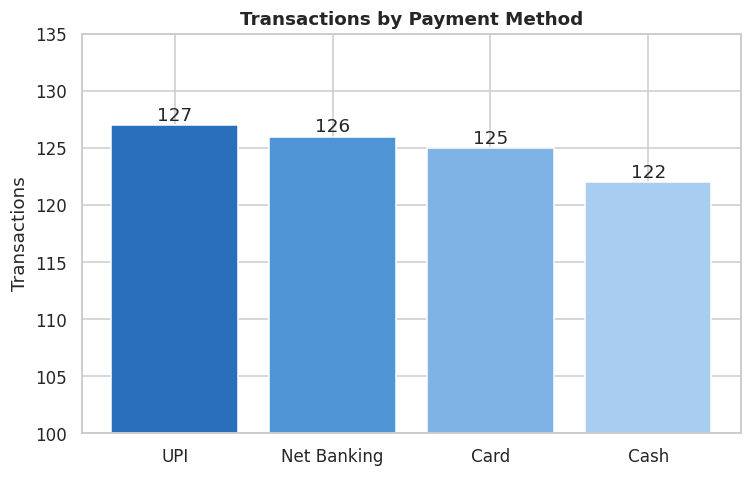

In [12]:
pay = df["Payment"].value_counts().to_frame("Transactions")
pay["Share_%"] = (pay["Transactions"]/len(df)*100).round(1)
pay["Sales"] = df.groupby("Payment")["Sales"].sum().round(2)
display(pay)

fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(pay.index, pay["Transactions"], color=["#2a6fbb","#4f95d6","#7fb3e6","#a9cdf0"])
ax.set_ylim(100, 135); ax.set_title("Transactions by Payment Method"); ax.set_ylabel("Transactions")
for b_, v in zip(bars, pay["Transactions"]): ax.text(b_.get_x()+b_.get_width()/2, v+0.4, v, ha="center")
plt.tight_layout(); plt.savefig("charts/05_payment_methods.png"); plt.show()

**UPI** is the most used method with **127 transactions**, but the difference is tiny: Net Banking has 126, Card 125 and Cash 122. Customers use all four methods almost equally, so the store should keep **all** payment options available rather than favour only one. (The y-axis above starts at 100 to make the small gaps visible.)

### Q5. Do Members spend more than Normal customers?

,Customers,Avg_Transaction,Median,Total
Customer Type,,,,
Member,296,483.14,314.46,143009.30
Normal,204,497.07,352.56,101401.78


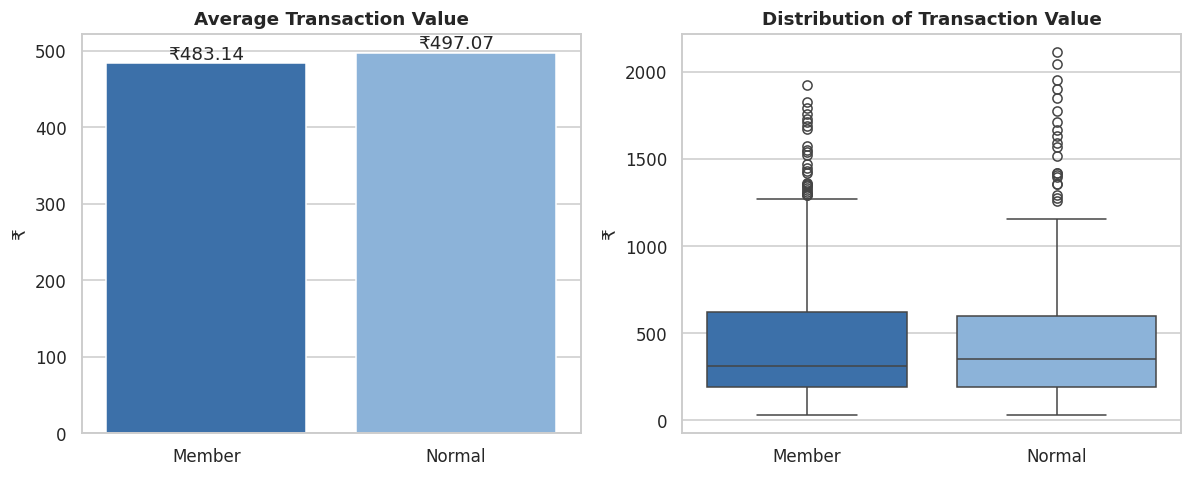

In [13]:
cust = df.groupby("Customer Type")["Sales"].agg(Customers="count", Avg_Transaction="mean",
                                                 Median="median", Total="sum").round(2)
display(cust)

fig, axes = plt.subplots(1, 2, figsize=(11,4.5))
sns.barplot(x=cust.index, y=cust["Avg_Transaction"], ax=axes[0], palette=["#2a6fbb","#7fb3e6"], hue=cust.index, legend=False)
axes[0].set_title("Average Transaction Value"); axes[0].set_ylabel("₹"); axes[0].set_xlabel("")
for i, v in enumerate(cust["Avg_Transaction"]): axes[0].text(i, v+5, f"₹{v:,.2f}", ha="center")
sns.boxplot(data=df, x="Customer Type", y="Sales", ax=axes[1], palette=["#2a6fbb","#7fb3e6"], hue="Customer Type", legend=False)
axes[1].set_title("Distribution of Transaction Value"); axes[1].set_ylabel("₹"); axes[1].set_xlabel("")
plt.tight_layout(); plt.savefig("charts/06_member_vs_normal.png"); plt.show()

In [14]:
# Is the difference meaningful? Welch t-test (needs scipy)
try:
    from scipy import stats
    m = df.loc[df["Customer Type"]=="Member","Sales"]; n = df.loc[df["Customer Type"]=="Normal","Sales"]
    t, p = stats.ttest_ind(m, n, equal_var=False)
    print(f"Welch t-test: t = {t:.3f}, p-value = {p:.3f}")
    print("Difference is statistically significant" if p < 0.05 else "Difference is NOT statistically significant (p >= 0.05)")
except ImportError:
    print("scipy not installed - skipping significance test")

Welch t-test: t = -0.346, p-value = 0.730
Difference is NOT statistically significant (p >= 0.05)


**No** — Members average **₹483.14** per transaction and Normal customers **₹497.07**. The ₹14 gap is small and the t-test shows it is not statistically significant, so Members do not spend more per visit. Members make up 59% of transactions (296 of 500), meaning the membership scheme brings **more visits**, not bigger bills. Membership offers should therefore aim to raise basket size (for example, bundle or minimum-spend offers).

### Q6. What is the average customer rating?

Average rating: 3.99 / 5


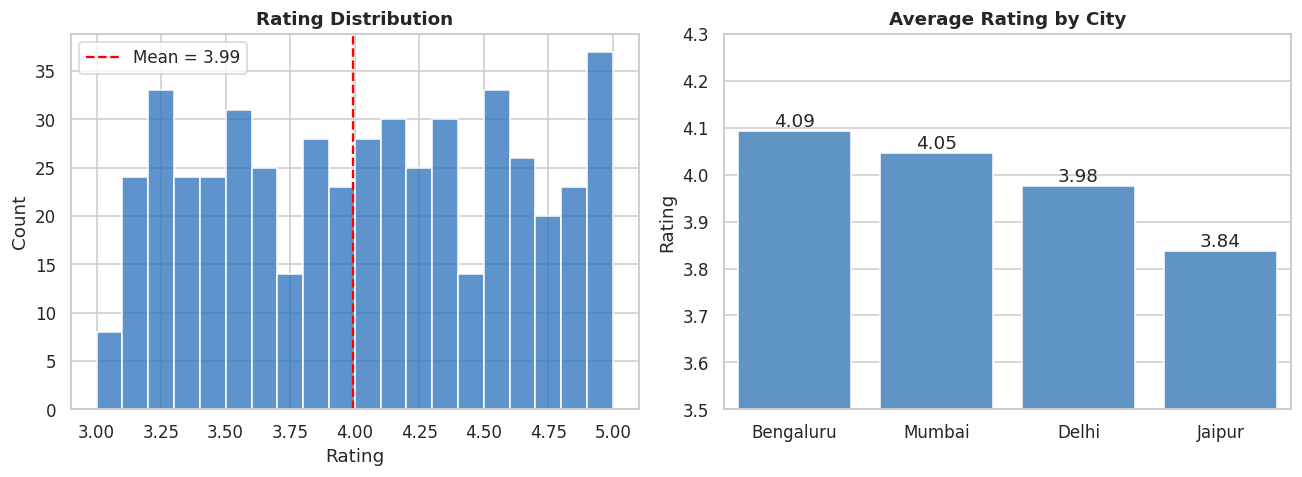

In [15]:
avg_rating = df["Rating"].mean()
print(f"Average rating: {avg_rating:.2f} / 5")

fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
sns.histplot(df["Rating"], bins=20, ax=axes[0], color="#2a6fbb")
axes[0].axvline(avg_rating, color="red", ls="--", label=f"Mean = {avg_rating:.2f}")
axes[0].set_title("Rating Distribution"); axes[0].legend()
r_branch = df.groupby("City")["Rating"].mean().sort_values(ascending=False)
sns.barplot(x=r_branch.index, y=r_branch.values, ax=axes[1], color="#4f95d6")
axes[1].set_ylim(3.5, 4.3); axes[1].set_title("Average Rating by City"); axes[1].set_ylabel("Rating"); axes[1].set_xlabel("")
for i, v in enumerate(r_branch.values): axes[1].text(i, v+0.01, f"{v:.2f}", ha="center")
plt.tight_layout(); plt.savefig("charts/07_ratings.png"); plt.show()

In [16]:
print("Average rating by category:")
print(df.groupby("Category")["Rating"].mean().sort_values().round(2))
print("\nCorrelation between Rating and Sales:", round(df["Rating"].corr(df["Sales"]), 3))
print("Share of ratings below 3.5:", f"{(df['Rating'] < 3.5).mean()*100:.1f}%")

Average rating by category:
Category
Fruits           3.83
Grocery          3.94
Personal Care    3.95
Beverages        3.96
Vegetables       3.99
Dairy            4.03
Snacks           4.11
Bakery           4.24
Name: Rating, dtype: float64

Correlation between Rating and Sales: -0.047
Share of ratings below 3.5: 22.6%


The average rating is **3.99 / 5**, with ratings spread across the 3–5 range. Rating has almost no link with bill value (correlation ≈ −0.05). Branch A (Jaipur) has the lowest rating (3.84) as well as the lowest sales, while Bengaluru is highest (4.09). About 23% of transactions are rated below 3.5 — the place where service improvement can have the most effect.

## 7. Additional Analysis

### Monthly sales trend

,Sales
Month,
2026-01,43415.53
2026-02,30068.15
2026-03,37306.42
2026-04,52569.77
2026-05,42542.31
2026-06,35041.46
2026-07,3467.44


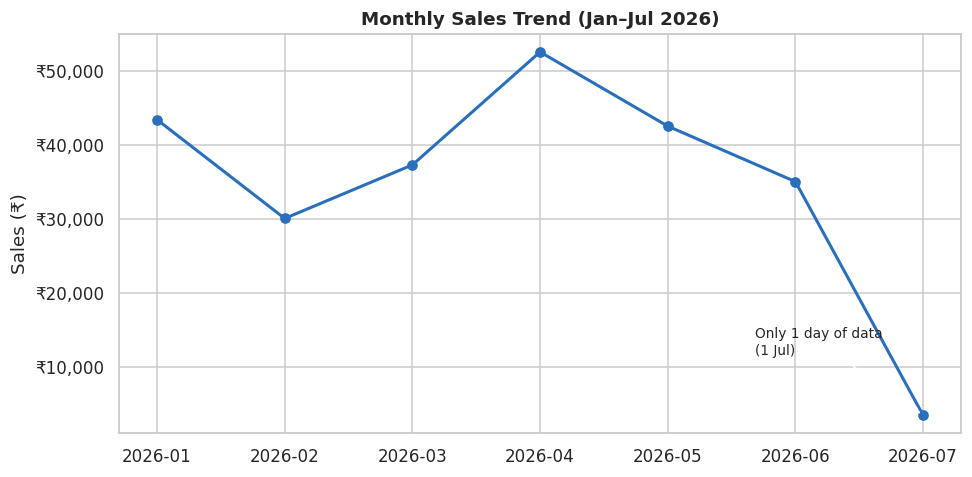

In [17]:
monthly = df.groupby("Month")["Sales"].sum().round(2)
display(monthly.to_frame("Sales"))

fig, ax = plt.subplots(figsize=(9,4.5))
ax.plot(monthly.index, monthly.values, marker="o", color="#2a6fbb", lw=2)
ax.yaxis.set_major_formatter(rupee); ax.set_title("Monthly Sales Trend (Jan–Jul 2026)"); ax.set_ylabel("Sales (₹)")
ax.annotate("Only 1 day of data\n(1 Jul)", xy=(monthly.index[-1], monthly.values[-1]), xytext=(-110, 40),
            textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=9)
plt.tight_layout(); plt.savefig("charts/08_monthly_trend.png"); plt.show()

April is the strongest month (₹52,570) and February the weakest full month (₹30,068). July contains only one day of data, so it should not be compared with the other months.

### Gender and category

,Transactions,Total,Average
Gender,,,
Female,255,123954.12,486.09
Male,245,120456.96,491.66


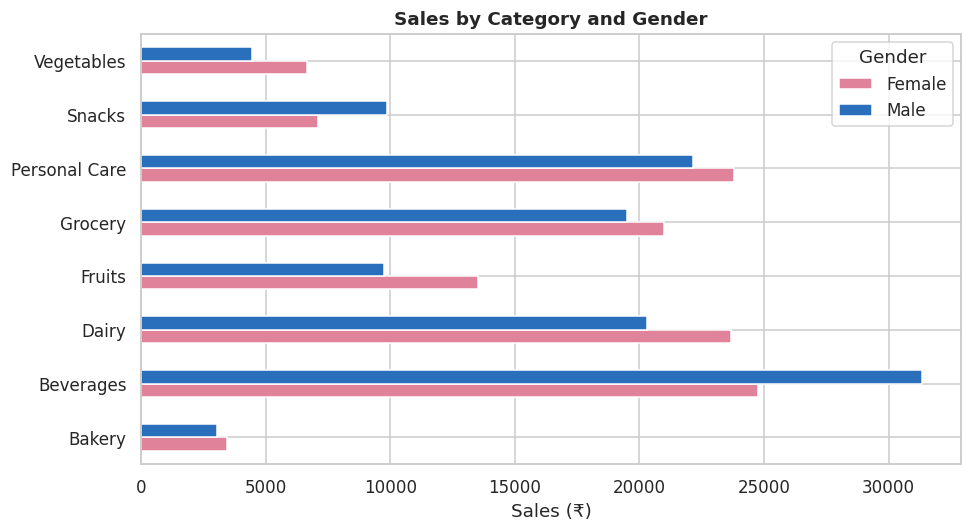

In [18]:
g = df.groupby("Gender")["Sales"].agg(Transactions="count", Total="sum", Average="mean").round(2)
display(g)
gc = df.pivot_table(index="Category", columns="Gender", values="Sales", aggfunc="sum")
gc.plot(kind="barh", figsize=(9,5), color=["#e0829a","#2a6fbb"])
plt.title("Sales by Category and Gender"); plt.xlabel("Sales (₹)"); plt.ylabel("")
plt.tight_layout(); plt.savefig("charts/09_gender_category.png"); plt.show()

Male and female customers contribute almost equally and have similar average bills (₹492 vs ₹486), so gender is not a useful basis for targeting.

### Price vs. volume: what drives sales?

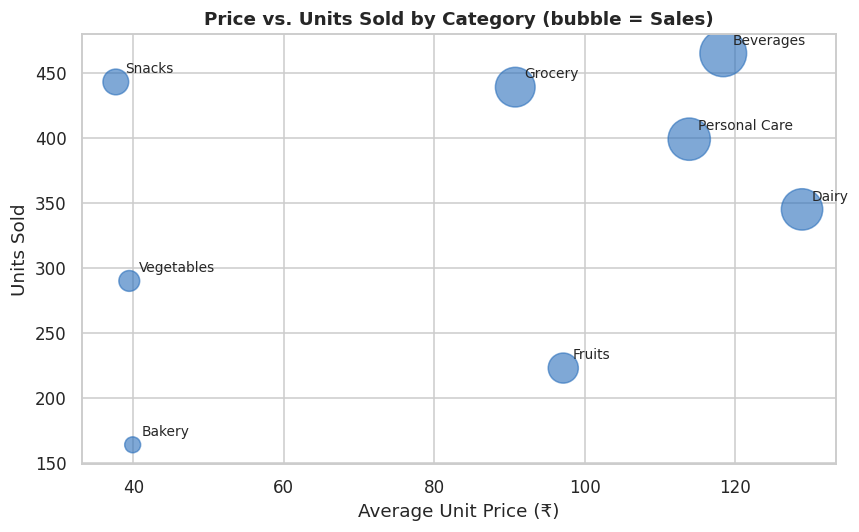

,Avg_Price,Units,Sales
Category,,,
Beverages,118.38,465,56108.24
Personal Care,113.86,399,45943.96
Dairy,128.85,345,43992.00
Grocery,90.74,439,40470.47
Fruits,97.12,223,23263.17
Snacks,37.66,443,16992.97
Vegetables,39.45,290,11124.17
Bakery,39.90,164,6516.10


In [19]:
pv = df.groupby("Category").agg(Avg_Price=("Unit Price","mean"), Units=("Quantity","sum"), Sales=("Sales","sum")).round(2)
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(pv["Avg_Price"], pv["Units"], s=pv["Sales"]/60, alpha=0.6, color="#2a6fbb")
for name, r in pv.iterrows(): ax.annotate(name, (r["Avg_Price"], r["Units"]), xytext=(6,6), textcoords="offset points", fontsize=9)
ax.set_xlabel("Average Unit Price (₹)"); ax.set_ylabel("Units Sold"); ax.set_title("Price vs. Units Sold by Category (bubble = Sales)")
plt.tight_layout(); plt.savefig("charts/10_price_vs_volume.png"); plt.show()
pv.sort_values("Sales", ascending=False)

Sales depend more on price than on volume: Snacks sell about as many units as Grocery (443 vs 439) but earn less than half, because the average unit price is ₹38 against ₹91. Beverages, Personal Care and Dairy lead because they combine good volume with high unit prices.

## 8. Key Insights

| # | Question | Finding |
|---|---|---|
| 1 | Top product | **Cheese** – ₹27,906.30 (Coffee ₹27,694.87 and Shampoo ₹27,497.48 are almost level) |
| 2 | Best branch | **Branch C (Mumbai)** – ₹72,469.45 (29.7% of sales) |
| 3 | Top category | **Beverages** – ₹56,108.24 (23.0%) |
| 4 | Payment method | **UPI** – 127 transactions, but all four methods are within 5 transactions of each other |
| 5 | Member vs Normal | Members ₹483.14 vs Normal ₹497.07 – **Members do not spend more** (difference not significant) |
| 6 | Rating | **3.99 / 5** |

## 9. Business Recommendations
1. **Stock priority:** keep deep stock of Cheese, Coffee, Shampoo and the Beverages, Personal Care and Dairy categories — they bring about 60% of revenue.
2. **Learn from Branch C:** study what drives its higher transaction count (location, timing, offers) and test those practices in Branch A (Jaipur), the lowest-selling branch.
3. **Payments:** keep UPI, Net Banking, Card and Cash all active; no single method dominates.
4. **Membership:** members visit more often but do not spend more per visit, so introduce minimum-spend or bundle rewards to increase basket value.
5. **Customer service:** start with Branch A (Jaipur, rating 3.84) and the ~23% of transactions rated below 3.5 — use feedback follow-up and staff training to lift the 3.99 average.
6. **Promotions:** use low-price, high-volume items (Vegetables, Snacks, Bakery) as add-on offers with high-value items.

## 10. Limitations
- The dataset is small (500 transactions) and covers only Jan 1 – Jul 1, 2026.
- July has only one day of data, so month-to-month comparison excludes it.
- There is no customer ID, so repeat-visit behaviour cannot be measured.

## 11. Conclusion
The analysis turns raw sales records into clear decisions on stock, branch strategy, payments, membership and service quality. Revenue is concentrated in a few high-priced categories and in Branch C, spending is the same across customer types, and customer satisfaction is good (3.99/5) with room to improve.